In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time
import platform
import sklearn

from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

sns.set_theme(style="whitegrid")

In [3]:
DATA_DIR = Path("../data")
RESULTS_DIR = Path("../results")
FIGURES_DIR = Path("../figures")
LOGS_DIR = Path("../logs")

FIGURES_DIR.mkdir(exist_ok=True)
LOGS_DIR.mkdir(exist_ok=True)

df = pd.read_csv(
    DATA_DIR / "PhiUSIIL_Preprocessed.csv"
)

with open(RESULTS_DIR / "feature_config.json", "r") as f:
    config = json.load(f)

split = np.load(
    RESULTS_DIR / "baseline_split.npz"
)

full_features = config["full_features"]

train_idx = split["train_idx"]
test_idx = split["test_idx"]

print("Dimensi dataset:", df.shape)
print("Jumlah fitur:", len(full_features))
print("Random state:", config["random_state"])
print("Test size:", config["test_size"])

Dimensi dataset: (235370, 56)
Jumlah fitur: 47
Random state: 42
Test size: 0.3


In [4]:
X = df[full_features]

y = df["label"].map({
    0: 1,
    1: 0
})

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

assert set(train_idx).isdisjoint(test_idx)
assert not y.isna().any()

print("X Training:", X_train.shape)
print("X Testing:", X_test.shape)

print("y Training:", y_train.shape)
print("y Testing:", y_test.shape)

X Training: (164759, 47)
X Testing: (70611, 47)
y Training: (164759,)
y Testing: (70611,)


In [5]:
class_distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts()
})

class_distribution.index = (
    class_distribution.index.map({
        0: "Legitimate",
        1: "Phishing"
    })
)

class_distribution

,Training,Testing
label,,
Legitimate,94395,40455
Phishing,70364,30156


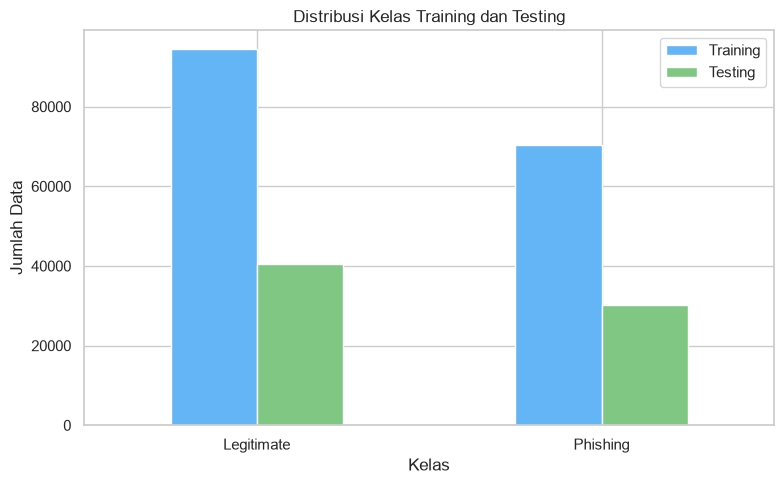

In [6]:
class_distribution.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#64B5F6", "#81C784"]
)

plt.title("Distribusi Kelas Training dan Testing")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

In [8]:
def evaluate_model(
    model_name,
    model,
    X_train,
    X_test,
    y_train,
    y_test
):

    # Training
    start_train = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_train

    # Prediction
    start_inference = time.perf_counter()

    y_pred = model.predict(X_test)

    inference_time = time.perf_counter() - start_inference

    # Prediction probability
    y_prob = model.predict_proba(X_test)[:, 1]

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Evaluation metrics
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Training Time (s)": training_time,
        "Inference Time (s)": inference_time,
        "Inference per Sample (ms)": (
            inference_time / len(X_test)
        ) * 1000,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    return metrics, y_pred, y_prob

In [9]:
results = []
predictions = {}
probabilities = {}

for model_name, model in models.items():

    print(f"Training {model_name}...")

    metrics, y_pred, y_prob = evaluate_model(
        model_name,
        model,
        X_train,
        X_test,
        y_train,
        y_test
    )

    results.append(metrics)

    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    print(f"{model_name} selesai.")
    print("-" * 50)

Training Logistic Regression...
Logistic Regression selesai.
--------------------------------------------------
Training Random Forest...
Random Forest selesai.
--------------------------------------------------


In [10]:
results_df = pd.DataFrame(results)

results_df.round(6)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s),Inference Time (s),Inference per Sample (ms),TN,FP,FN,TP
0,Logistic Regression,0.999278,0.999768,0.998541,0.999154,0.999964,0.390694,0.022785,0.000323,40448,7,44,30112
1,Random Forest,0.999830,0.999867,0.999735,0.999801,0.999998,4.184473,0.084865,0.001202,40451,4,8,30148


In [11]:
for model_name, y_pred in predictions.items():

    print("=" * 60)

    print(model_name)

    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        digits=6,
        zero_division=0
    ))

Logistic Regression
              precision    recall  f1-score   support

  Legitimate   0.998913  0.999827  0.999370     40455
    Phishing   0.999768  0.998541  0.999154     30156

    accuracy                       0.999278     70611
   macro avg   0.999340  0.999184  0.999262     70611
weighted avg   0.999278  0.999278  0.999278     70611

Random Forest
              precision    recall  f1-score   support

  Legitimate   0.999802  0.999901  0.999852     40455
    Phishing   0.999867  0.999735  0.999801     30156

    accuracy                       0.999830     70611
   macro avg   0.999835  0.999818  0.999826     70611
weighted avg   0.999830  0.999830  0.999830     70611



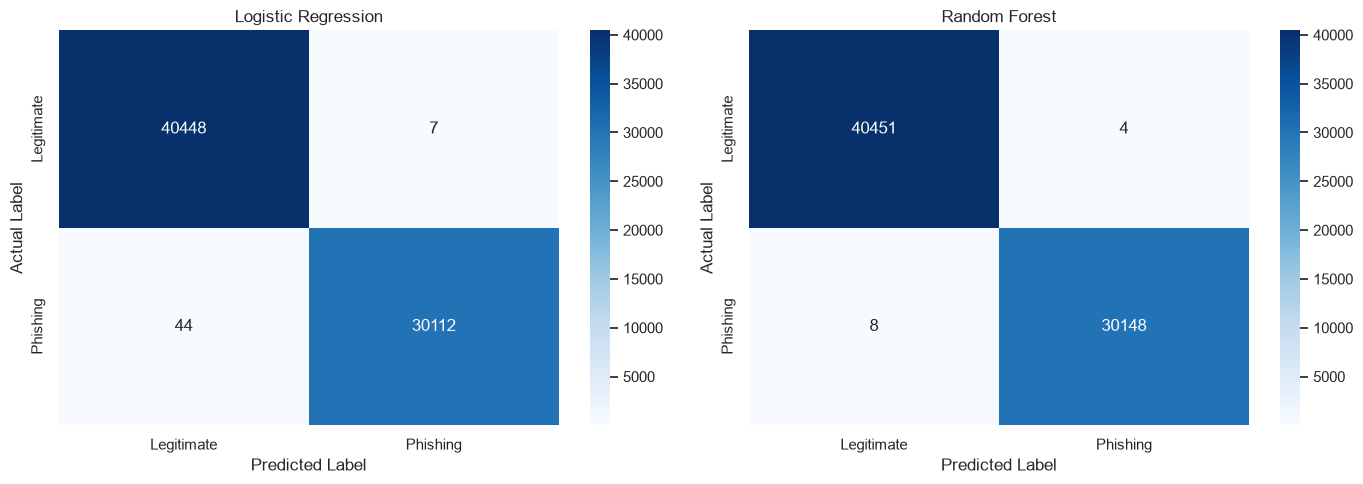

In [12]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for ax, (model_name, y_pred) in zip(
    axes,
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Phishing"],
        yticklabels=["Legitimate", "Phishing"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

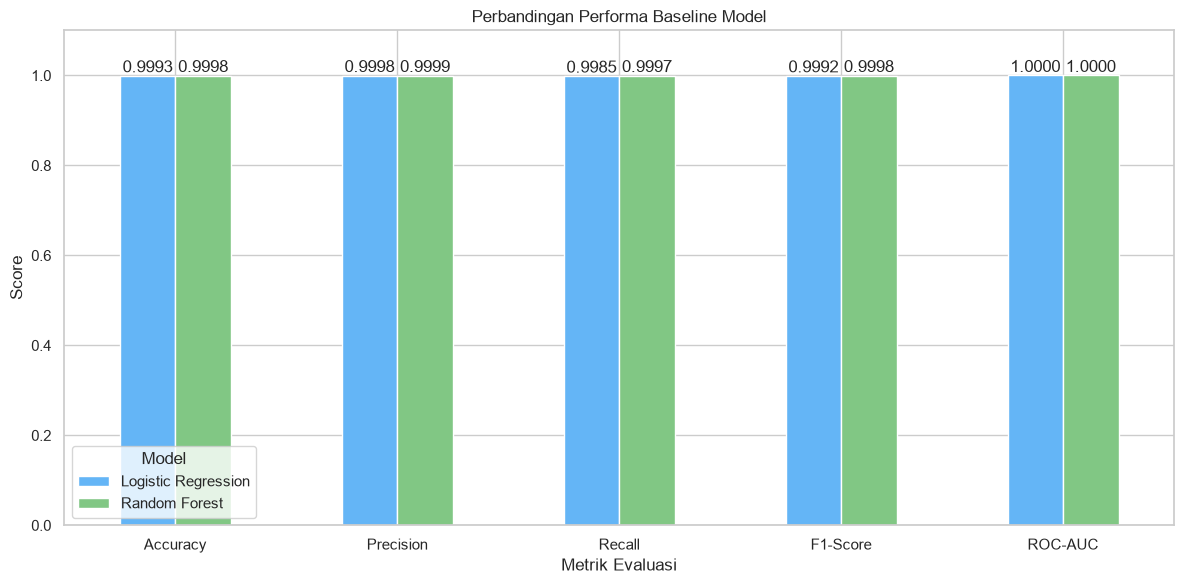

In [13]:
metrics_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

performance_df = (
    results_df
    .set_index("Model")[metrics_columns]
    .T
)

ax = performance_df.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#64B5F6", "#81C784"]
)

plt.title("Perbandingan Performa Baseline Model")
plt.xlabel("Metrik Evaluasi")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

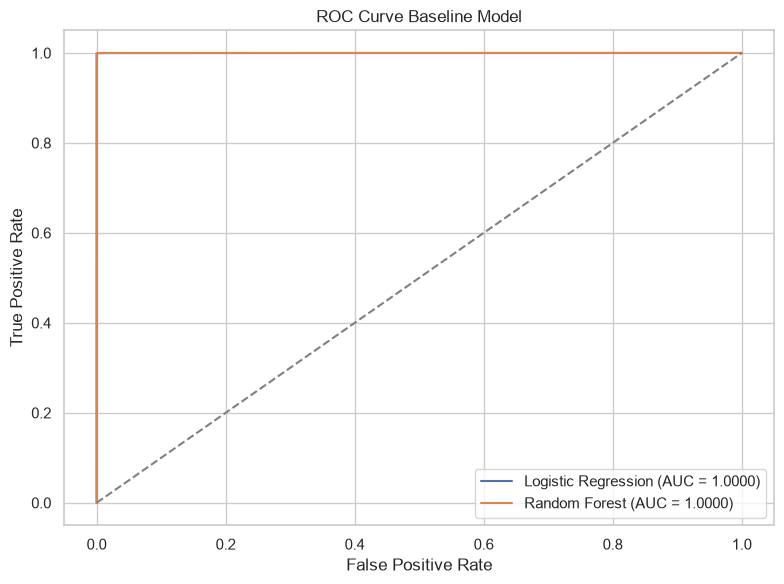

In [14]:
plt.figure(figsize=(8, 6))

for model_name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.title("ROC Curve Baseline Model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

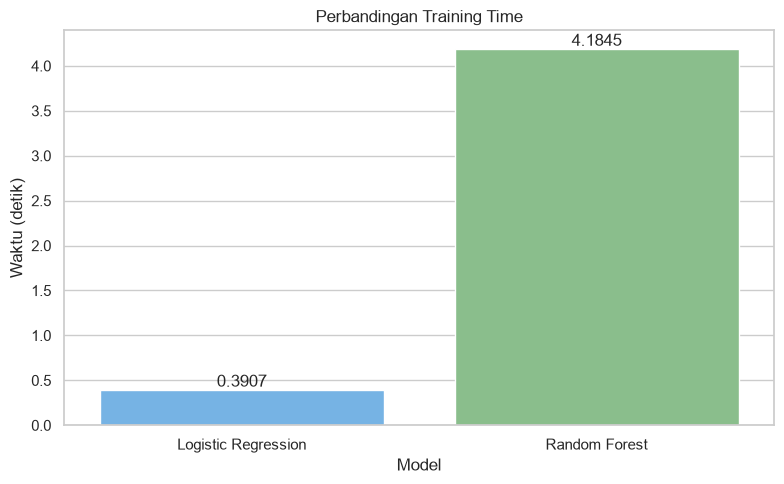

In [15]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=results_df,
    x="Model",
    y="Training Time (s)",
    hue="Model",
    palette=["#64B5F6", "#81C784"],
    legend=False
)

plt.title("Perbandingan Training Time")
plt.xlabel("Model")
plt.ylabel("Waktu (detik)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_training_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

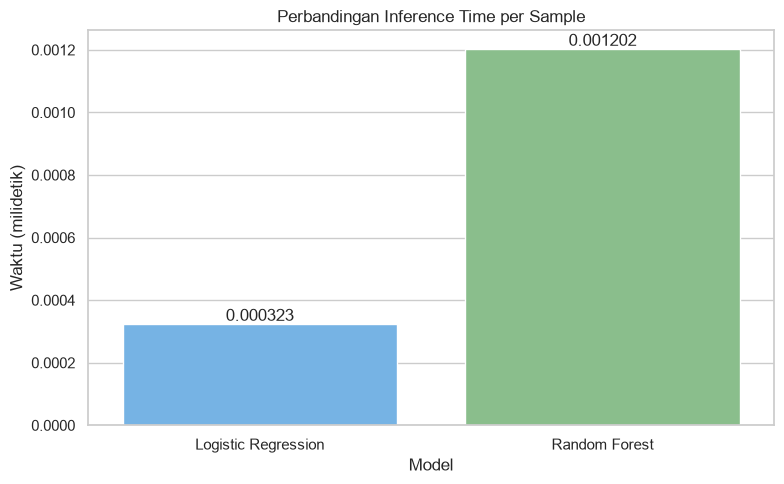

In [16]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=results_df,
    x="Model",
    y="Inference per Sample (ms)",
    hue="Model",
    palette=["#64B5F6", "#81C784"],
    legend=False
)

plt.title("Perbandingan Inference Time per Sample")
plt.xlabel("Model")
plt.ylabel("Waktu (milidetik)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.6f")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_inference_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
results_df["Scenario"] = "A"
results_df["Feature Type"] = "Full Features"
results_df["Validation"] = "Random Split"
results_df["Number of Features"] = len(full_features)
results_df["Training Samples"] = len(X_train)
results_df["Testing Samples"] = len(X_test)
results_df["Random State"] = 42

results_df.to_csv(
    RESULTS_DIR / "baseline_metrics.csv",
    index=False
)

print("Hasil baseline berhasil disimpan.")

Hasil baseline berhasil disimpan.


In [18]:
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Model dengan F1-Score tertinggi:")
print("Model:", best_model["Model"])

print("Accuracy:", best_model["Accuracy"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1-Score:", best_model["F1-Score"])
print("ROC-AUC:", best_model["ROC-AUC"])

Model dengan F1-Score tertinggi:
Model: Random Forest
Accuracy: 0.9998300548073247
Precision: 0.9998673388166622
Recall: 0.9997347128266348
F1-Score: 0.9998010214233601
ROC-AUC: 0.9999984688034859


In [19]:
from pathlib import Path

print("Working Directory:", Path.cwd())
print("Logs Directory:", LOGS_DIR.resolve())
print("Apakah folder logs ada?", LOGS_DIR.exists())

log_path = LOGS_DIR / "baseline_run_log.md"
print("Apakah file log ada?", log_path.exists())

Working Directory: c:\kuliah\Kuliah\semester 5\BINDO\tgas Akhir\TKKI-Phising-Detection\notebooks
Logs Directory: C:\kuliah\Kuliah\semester 5\BINDO\tgas Akhir\TKKI-Phising-Detection\logs
Apakah folder logs ada? True
Apakah file log ada? False


In [20]:
from pathlib import Path
from datetime import datetime
import platform
import pandas as pd
import numpy as np
import sklearn

# Lokasi folder
PROJECT_DIR = Path.cwd().parent
LOGS_DIR = PROJECT_DIR / "logs"
RESULTS_DIR = PROJECT_DIR / "results"

LOGS_DIR.mkdir(parents=True, exist_ok=True)

# Ambil hasil eksperimen yang sudah disimpan
results_df = pd.read_csv(
    RESULTS_DIR / "baseline_metrics.csv"
)

# Membuat isi log
log_content = f"""
# Baseline Run Log

## 1. Informasi Penelitian

**Judul:**
Evaluasi Pengaruh Fitur URL-Only dan Validasi Berbasis Domain terhadap Deteksi Phishing Menggunakan Machine Learning

**Dataset:** PhiUSIIL Phishing URL Dataset

**Skenario:** A — Full Features + Random Split

**Tanggal pencatatan:** {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

## 2. Environment

- Operating System: {platform.platform()}
- Python Version: {platform.python_version()}
- Pandas Version: {pd.__version__}
- NumPy Version: {np.__version__}
- Scikit-learn Version: {sklearn.__version__}

## 3. Konfigurasi Eksperimen

- Dataset awal: 235.795 sampel
- Dataset setelah menghapus URL duplikat: 235.370 sampel
- Full Features: 47 fitur
- Training: 70%
- Testing: 30%
- Random State: 42
- Positive Class: Phishing

## 4. Konfigurasi Model

### Logistic Regression
- StandardScaler
- max_iter = 1000
- random_state = 42

### Random Forest
- n_estimators = 100
- random_state = 42
- n_jobs = -1

## 5. Hasil Eksperimen

"""

# Menambahkan hasil kedua model
for _, row in results_df.iterrows():

    log_content += f"""
### {row['Model']}

- Accuracy: {row['Accuracy']:.6f}
- Precision: {row['Precision']:.6f}
- Recall: {row['Recall']:.6f}
- F1-Score: {row['F1-Score']:.6f}
- ROC-AUC: {row['ROC-AUC']:.6f}
- Training Time: {row['Training Time (s)']:.6f} detik
- Inference Time: {row['Inference Time (s)']:.6f} detik
- True Negative: {int(row['TN'])}
- False Positive: {int(row['FP'])}
- False Negative: {int(row['FN'])}
- True Positive: {int(row['TP'])}

"""

log_content += """
## 6. Kesimpulan

Berdasarkan hasil eksperimen baseline, Random Forest
menghasilkan performa klasifikasi yang lebih tinggi
dibandingkan Logistic Regression.

Namun, Logistic Regression memiliki waktu pelatihan
dan inferensi yang lebih rendah.

Performa kedua model masih perlu dievaluasi menggunakan
URL-only features dan domain-grouped split.

## 7. Catatan Metodologis

- Dataset menggunakan PhiUSIIL dari Kaggle.
- URL duplikat dihapus sebelum pembagian data.
- Fitur yang berpotensi menyebabkan data leakage dikecualikan.
- Pembagian data menggunakan stratified random split.
- Eksperimen ini merupakan baseline penelitian yang telah
  diadaptasi, bukan reproduksi identik GitHub referensi.
"""

# Simpan file
log_path = LOGS_DIR / "baseline_run_log.md"

log_path.write_text(
    log_content,
    encoding="utf-8"
)

print("Baseline Run Log berhasil dibuat!")
print("Lokasi:", log_path.resolve())
print("File ditemukan:", log_path.exists())
print("Ukuran file:", log_path.stat().st_size, "bytes")

Baseline Run Log berhasil dibuat!
Lokasi: C:\kuliah\Kuliah\semester 5\BINDO\tgas Akhir\TKKI-Phising-Detection\logs\baseline_run_log.md
File ditemukan: True
Ukuran file: 2261 bytes
